In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model, plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf

I0000 00:00:1794304025.590140 1291375 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794304025.622163 1291375 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794304026.330618 1291375 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h1> Import Data

Text(0.5, 0.98, 'All Data')

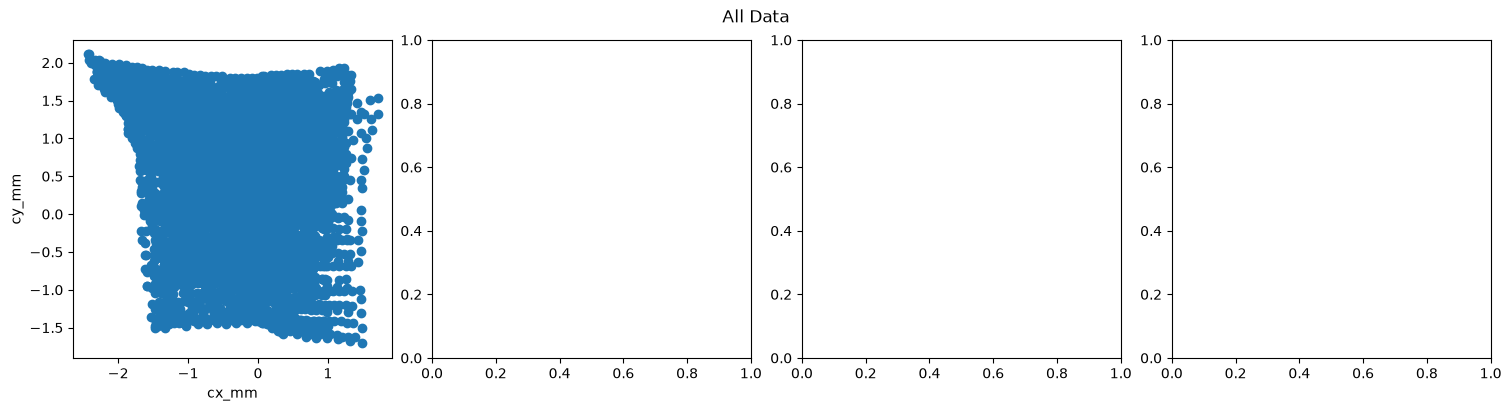

In [4]:
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_list = [data_3]

fig, axs = plt.subplots(1, 4, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
fig.suptitle("All Data")

<h2> Remove NaNs

In [5]:
all_data = data_3.dropna()

data_3.Name = "data_3"

<h2> Create StandardScalers based on all data

In [6]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

<h2>Scale all datasets

In [7]:
X_scaled = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled = scalerY.transform(all_data[["s0", "s1", "s2"]])

<h2> Build Model

In [ ]:
# model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1])
# model.summary() #investigate

W0000 00:00:1794304034.831808 1291375 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,531 (25.51 KB)

 Trainable params: 6,531 (25.51 KB)

 Non-trainable params: 0 (0.00 B)

<h1> Training on data_1 - 16thOct

<h2>TimeSeriesSplit

In [9]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

In [16]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),#  kernel_regularizer='l1'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    model.summary()

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    # callbacks = [
    # tf.keras.callbacks.EarlyStopping(
    #     monitor='val_loss',
    #     patience=patience,
    #     restore_best_weights=True
    # )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    # callbacks=callbacks
    )
    # print(patience)
    return history

Fold 0:
  Train: index=0 to 1289 
  Test:  index=1290 to 2578


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 195 (780.00 B)

 Trainable params: 195 (780.00 B)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 195 (780.00 B)

 Trainable params: 195 (780.00 B)

 Non-trainable params: 0 (0.00 B)


Fold: 1 Results (scaled):
  Overall R2:  0.7679
  Weighted R2: 0.7983
MSE scores for each fold: [0.1117459237575531, 0.16996197402477264]


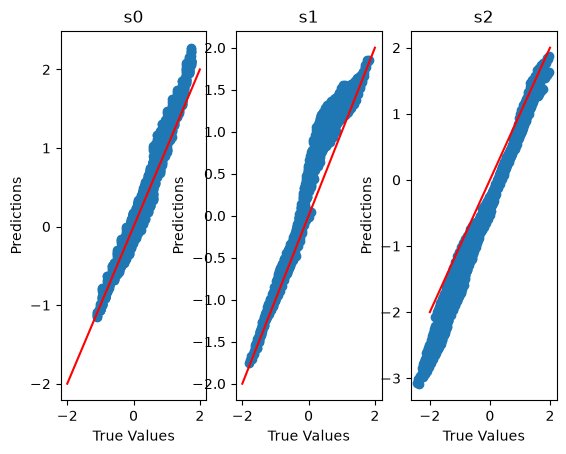

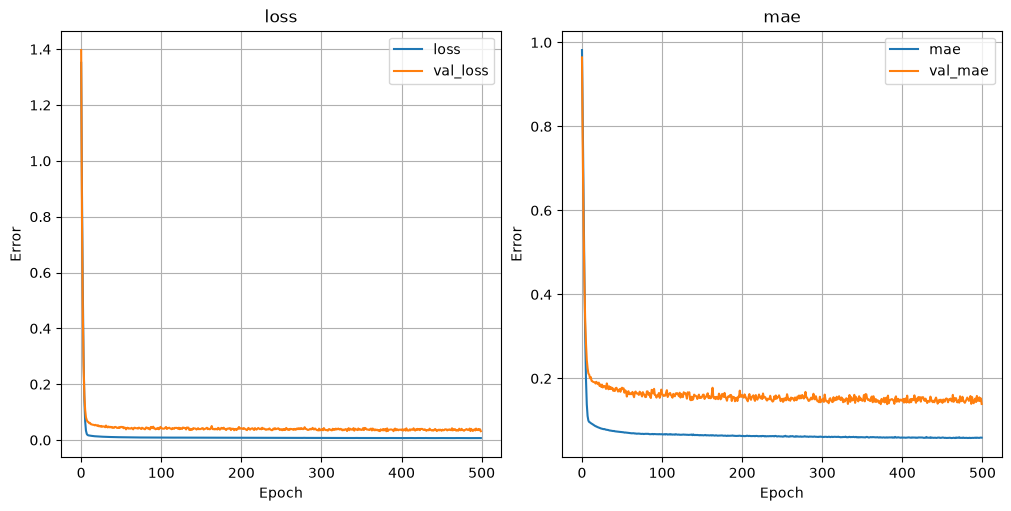

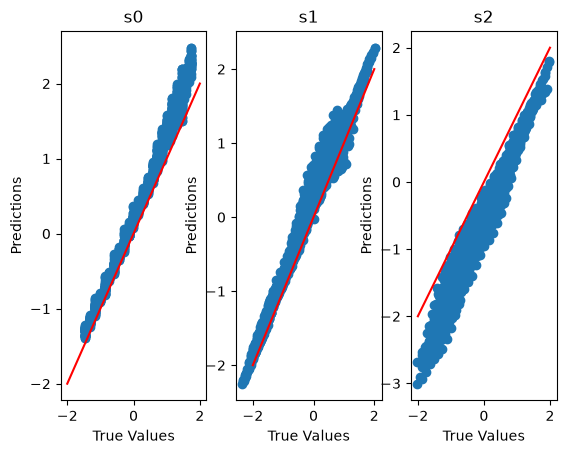

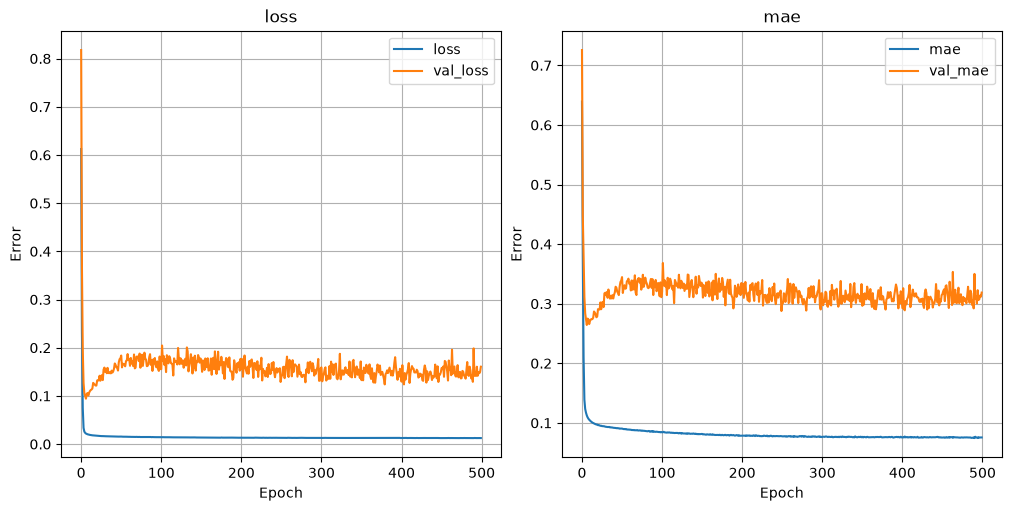

In [17]:
# model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1])

scores = []

X = X_scaled
y = y_scaled

tscv = TimeSeriesSplit(n_splits=2) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_scaled.shape[1], y_scaled.shape[1]) #instantiate new model each time to see difference

    history = train_model(model, X_train, y_train, verbose=0, epochs=500) #, patience=10)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)

print("MSE scores for each fold:", scores)

In [ ]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test)

In [ ]:
plot_motors(y_test_inverse, y_pred_inverse, [-10000,10000])

In [ ]:
#finding data that needs fixing 
y_pred_df = pd.DataFrame(y_pred_inverse)

y_pred_df["s0_true"] = y_test_inverse[:,0]
y_pred_df["s1_true"] = y_test_inverse[:,1]
y_pred_df["s2_true"] = y_test_inverse[:,2]

y_pred_df["s0_diff"] = y_pred_df["s0_true"] - y_pred_df[0]
y_pred_df["s1_diff"] = y_pred_df["s1_true"] - y_pred_df[1]
y_pred_df["s2_diff"] = y_pred_df["s2_true"] - y_pred_df[2]
print(y_pred_df.index[y_pred_df["s1_diff"] == max(y_pred_df["s1_diff"])])
print(y_pred_df.index[y_pred_df["s2_diff"] == max(y_pred_df["s2_diff"])])
y_pred_df